# Pregunta 3 · Detección de fauna CCT-20 con YOLOv8
**Notebook de Grupo 2 · UNI · 2026-II**

> Versión de entrega construida a partir del notebook experimental original (116 celdas). **No contiene resultados recalculados ni inventados:** los resultados que muestra se leen de los CSV guardados en Google Drive.

**Objetivo:** analizar detección de fauna, generalización a cámaras no vistas, robustez por tamaño y oclusión, sensibilidad al fondo y monitoreo ecológico. Modelo principal YOLOv8s; referencia YOLOv8n.

**Uso habitual sin gastar GPU:** ejecutar desde la configuración hasta las figuras. Todos los experimentos costosos están desactivados por defecto. **No pulsar «Ejecutar todo» con los interruptores de entrenamiento/reprocesamiento activados.**

**Procedencia:** CCT-20/ECCV 2018; se trabaja con el archivo original de imágenes comprimido y los JSON originales, localizados en `MyDrive/examen_yolo/raw`. La preparación utiliza 14 especies ordenadas alfabéticamente, y trata explícitamente los negativos solo-vehículo del conjunto de entrenamiento.

## 0 · Guía y dependencias

Orden de lectura: **configuración → auditoría/preparación (opcional) → entrenamiento (opcional) → evaluación (opcional) → análisis de CSV → figuras finales → conclusiones**.

Todas las rutas se declaran en una sola celda. El contenido de `/content` es **temporal**; los modelos, anotaciones manuales, CSV y figuras residen en Drive. Los datos de TEST **no se usan para actualizar pesos**.

Versión registrada de Ultralytics para los entrenamientos finales: `8.4.184`. Si el paquete no está instalado, la primera celda instala esa versión; se registran las versiones del entorno para trazabilidad.

In [2]:
from google.colab import drive
from pathlib import Path
import os, sys, subprocess, importlib.util, json, tarfile, shutil, gc
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Image as IPyImage

if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics==8.4.184"])

import ultralytics
from ultralytics import YOLO
import torch

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("Dispositivo:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Mounted at /content/drive
Ultralytics: 8.4.184
PyTorch: 2.11.0+cpu
Dispositivo: CPU


### 0.1 Configuración única y seguridad frente a ejecuciones accidentales

Para reanudar el trabajo **deja todos los interruptores pesados en `False`**. `GENERAR_FIGURAS=True` solo lee resultados existentes. Cambia `PREPARAR_DATASET` únicamente cuando sea necesario reconstruir las imágenes locales después de un reinicio de Colab. No cambia datos guardados en Drive salvo archivos de salida identificados.

In [3]:
BASE = Path("/content/drive/MyDrive/examen_yolo")
RAW = BASE / "raw"
ANOTACIONES_TAR = RAW / "eccv_18_annotations.tar.gz"
IMAGENES_TAR = RAW / "eccv_18_all_images_sm.tar.gz"
DATASET = Path("/content/cct20_final")          # temporal; reconstruible
RUNS = BASE / "runs"                        # persistente
RESULTADOS = BASE / "resultados_analisis"
OCLUSION = RESULTADOS / "oclusion_test"
RESPALDO_120 = OCLUSION / "imagenes_reanudar"
ARTICULO = BASE / "articulo_final"
TABLAS = ARTICULO / "tablas"
FIGURAS = ARTICULO / "figuras"

PESOS = {
    "YOLOv8n": RUNS / "final_l4_v1/weights/best.pt",
    "YOLOv8s": RUNS / "comparacion_yolov8s_l4/weights/best.pt",
}
ESPECIES = [
    "badger", "bird", "bobcat", "cat", "coyote", "deer", "dog",
    "fox", "opossum", "rabbit", "raccoon", "rodent", "skunk", "squirrel"
]
PARTICIONES = ("train", "cis_val", "trans_val", "cis_test", "trans_test")
CANTIDADES_ESPERADAS = {
    "train": 12099, "cis_val": 2619, "trans_val": 1594,
    "cis_test": 13085, "trans_test": 18698,
}

# Interruptores de reproducibilidad. POR DEFECTO NO UTILIZAN GPU.
PREPARAR_DATASET = False
ENTRENAR_MODELOS = False
RECALCULAR_TEST = False
RECALCULAR_OCLUSION = False
RECALCULAR_FONDO = False
GENERAR_FIGURAS = True

for carpeta in (RESULTADOS, ARTICULO, TABLAS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Proyecto:", BASE)
print("Modo seguro: solo lectura + generación de figuras")

Proyecto: /content/drive/MyDrive/examen_yolo
Modo seguro: solo lectura + generación de figuras


### 0.2 Inventario de resultados existentes

Una marca `FALTA` no implica pérdida de los resultados: puede señalar un nombre de archivo diferente o un experimento que todavía no se ha realizado. Las celdas de análisis posteriores comprueban sus propias dependencias.

In [4]:
INVENTARIO = {
    "Pesos finales YOLOv8n": PESOS["YOLOv8n"],
    "Pesos finales YOLOv8s": PESOS["YOLOv8s"],
    "Comparación TEST": RESULTADOS / "comparacion_yolov8n_vs_yolov8s_test.csv",
    "Especies nano CIS": RESULTADOS / "metricas_especies_cis_test.csv",
    "Especies nano TRANS": RESULTADOS / "metricas_especies_trans_test.csv",
    "Especies small CIS": RESULTADOS / "metricas_yolov8s_especies_cis_test.csv",
    "Especies small TRANS": RESULTADOS / "metricas_yolov8s_especies_trans_test.csv",
    "Robustez tamaño CIS": RESULTADOS / "robustez_tamano_cis_test.csv",
    "Robustez tamaño TRANS": RESULTADOS / "robustez_tamano_trans_test.csv",
    "Muestra 120 casos": OCLUSION / "muestra_oclusion_test.csv",
    "Inferencia oclusión": OCLUSION / "resultados_modelos_oclusion.csv",
    "Intervención fondo": OCLUSION / "experimento_fondo_yolov8s.csv",
    "Reporte ecológico": RESULTADOS / "ecologia_resumen_especies.csv",
}

inventario = pd.DataFrame([
    {"Recurso": n, "Estado": "OK" if p.is_file() else "FALTA", "Ruta": str(p)}
    for n, p in INVENTARIO.items()
])
display(inventario[["Recurso", "Estado"]])

,Recurso,Estado
0,Pesos finales YOLOv8n,OK
1,Pesos finales YOLOv8s,OK
2,Comparación TEST,OK
3,Especies nano CIS,OK
4,Especies nano TRANS,OK
5,Especies small CIS,OK
6,Especies small TRANS,OK
7,Robustez tamaño CIS,OK
8,Robustez tamaño TRANS,OK
9,Muestra 120 casos,OK


## 1 · Comprender las anotaciones originales

CCT-20 contiene imágenes agrupadas por ubicación/cámara y secuencia. Distinguimos `cis_*` (cámaras conocidas) y `trans_*` (cámaras nuevas). El código solo lee el TAR de anotaciones; **no descomprime imágenes**.

In [5]:
def cargar_json_cct20(particiones=PARTICIONES):
    """Lee JSON específicos del TAR sin extraerlo a disco."""
    if not ANOTACIONES_TAR.is_file():
        raise FileNotFoundError(f"Falta {ANOTACIONES_TAR}")
    nombres = {p: f"{p}_annotations.json" for p in particiones}
    resultado = {}
    with tarfile.open(ANOTACIONES_TAR, "r:gz") as archivo:
        miembros = {
            Path(m.name).name: m for m in archivo.getmembers()
            if m.isfile() and m.name.endswith(".json")
        }
        for particion, nombre in nombres.items():
            if nombre not in miembros:
                raise FileNotFoundError(f"No existe {nombre} dentro del TAR")
            with archivo.extractfile(miembros[nombre]) as entrada:
                resultado[particion] = json.load(entrada)
    return resultado

# Solo inspección; ligera comparada con procesar imágenes.
if ANOTACIONES_TAR.is_file():
    crudos = cargar_json_cct20()
    auditoria_original = pd.DataFrame([
        {
            "Particion": nombre,
            "Fotografias": len(datos["images"]),
            "Anotaciones": len(datos["annotations"]),
            "Camaras": len({str(im.get("location")) for im in datos["images"]}),
        }
        for nombre, datos in crudos.items()
    ])
    display(auditoria_original)
else:
    print("No está el TAR de anotaciones: se puede continuar con los CSV en Drive.")

,Particion,Fotografias,Anotaciones,Camaras
0,train,13553,14071,10
1,cis_val,3484,3582,10
2,trans_val,1725,1865,1
3,cis_test,15827,16395,10
4,trans_test,23275,24028,9


## 2 · Preparación reproducible de CCT-20 (opcional)

**Se ejecuta solo si `PREPARAR_DATASET=True`.** Reconstruye las particiones filtradas que usaron los entrenamientos finales, mantiene el orden alfabético de las 14 especies y realiza extracción selectiva en `/content`.

Reglas reproducidas del notebook original:
- Si existe fauna con cualquier caja faltante/inválida, **se excluye la imagen**, en vez de etiquetarla erróneamente como negativa.
- `car` sin fauna se incluye como **negativo en TRAIN** (668 fotografías), con archivo de etiqueta vacío. No se considera automáticamente «empty» desde el punto de vista ecológico: solo significa «sin cajas de fauna objetivo».
- Solo se admiten imágenes de categorías compatibles (animales válidos o `empty`); imágenes mezcladas con `car` u otras categorías excluidas se descartan.
- No hay ejemplos `empty` explícitos válidos en el TRAIN usado; para VAL/TEST los negativos deben proceder de anotaciones explícitas adecuadas.
- Las cinco particiones mantienen sus archivos independientes: TRAIN **no** incorpora ninguna fotografía de TEST.

**Advertencia:** la extracción de decenas de miles de fotografías puede ocupar espacio y lectura prolongada de TAR, aunque no consuma GPU.

In [6]:
def caja_yolo(bbox, ancho, alto):
    if bbox is None or ancho <= 0 or alto <= 0:
        return None
    x, y, w, h = map(float, bbox)
    if w <= 0 or h <= 0:
        return None
    x1 = max(0.0, min(x, ancho))
    y1 = max(0.0, min(y, alto))
    x2 = max(0.0, min(x + w, ancho))
    y2 = max(0.0, min(y + h, alto))
    if x2 <= x1 or y2 <= y1:
        return None
    return ((x1+x2)/(2*ancho), (y1+y2)/(2*alto),
            (x2-x1)/ancho, (y2-y1)/alto)


def seleccionar_dataset(datos_crudos):
    # Devuelve mapa nombre imagen -> partición / líneas de etiqueta.
    seleccion = {}
    estadisticas = []
    for split, datos in datos_crudos.items():
        categorias = {c["id"]: c["name"] for c in datos["categories"]}
        grupos = defaultdict(list)
        for ann in datos["annotations"]:
            grupos[ann["image_id"]].append(ann)
        cont = Counter()
        for im in datos["images"]:
            anns = grupos.get(im["id"], [])
            if not anns:
                cont["sin_anotaciones"] += 1
                continue
            nombres = {categorias[a["category_id"]] for a in anns}
            if nombres == {"car"} and split == "train":
                lineas = []
                cont["negativos_car"] += 1
            elif nombres == {"empty"}:
                lineas = []
                cont["negativos_empty"] += 1
            elif ("car" in nombres or "empty" in nombres or
                  not nombres.issubset(ESPECIES)):
                cont["categoria_no_elegible"] += 1
                continue
            else:
                W, H = float(im["width"]), float(im["height"])
                lineas = []
                for ann in anns:
                    box = caja_yolo(ann.get("bbox"), W, H)
                    if box is None:
                        lineas = []
                        break
                    clase = ESPECIES.index(categorias[ann["category_id"]])
                    lineas.append(f"{clase} " + " ".join(f"{x:.8f}" for x in box))
                if not lineas:
                    cont["sin_cajas_completas"] += 1
                    continue
            nombre = Path(im["file_name"]).name
            if nombre in seleccion:
                raise ValueError(f"Nombre de imagen duplicado: {nombre}")
            seleccion[nombre] = (split, lineas)
            cont["incluidas"] += 1
            cont["cajas"] += len(lineas)
        estadisticas.append({"Particion": split, **dict(cont)})
    return seleccion, pd.DataFrame(estadisticas).fillna(0)


def extraer_imagenes_seleccionadas(seleccion):
    pendientes = {
        nombre: split for nombre, (split, _) in seleccion.items()
        if not (DATASET / "images" / split / nombre).is_file()
    }
    if not pendientes:
        print("Todas las fotografías seleccionadas ya están en /content.")
        return
    if not IMAGENES_TAR.is_file():
        raise FileNotFoundError(IMAGENES_TAR)
    print("Imágenes por extraer:", len(pendientes))
    with tarfile.open(IMAGENES_TAR, "r|gz") as archivo:
        for miembro in archivo:
            if not miembro.isfile():
                continue
            nombre = Path(miembro.name).name
            if nombre not in pendientes:
                continue
            destino = DATASET / "images" / pendientes.pop(nombre) / nombre
            destino.parent.mkdir(parents=True, exist_ok=True)
            with archivo.extractfile(miembro) as origen, destino.open("wb") as salida:
                shutil.copyfileobj(origen, salida)
            if not pendientes:
                break
    if pendientes:
        raise FileNotFoundError(f"Faltan {len(pendientes)} fotografías en el TAR")


def guardar_yaml_yolo():
    base = {
        "path": str(DATASET),
        "train": "images/train",
        "val": "images/cis_val",
        "test": "images/cis_test",
        "names": {i: clase for i, clase in enumerate(ESPECIES)},
    }
    for nombre, cambios in {
        "data_cis.yaml": {},
        "data_trans.yaml": {"val": "images/trans_val"},
        "data_cis_test.yaml": {"test": "images/cis_test"},
        "data_trans_test.yaml": {"test": "images/trans_test"},
    }.items():
        with (DATASET / nombre).open("w", encoding="utf-8") as fh:
            yaml.safe_dump({**base, **cambios}, fh, sort_keys=False,
                           allow_unicode=True)


def preparar_dataset():
    datos = cargar_json_cct20()
    seleccion, conteos = seleccionar_dataset(datos)
    display(conteos)
    for split, esperado in CANTIDADES_ESPERADAS.items():
        actual = sum(s == split for s, _ in seleccion.values())
        if actual != esperado:
            raise ValueError(f"{split}: seleccionadas {actual}; esperadas {esperado}. Revisar filtros.")
    for split in PARTICIONES:
        (DATASET / "images" / split).mkdir(parents=True, exist_ok=True)
        (DATASET / "labels" / split).mkdir(parents=True, exist_ok=True)
    for nombre, (split, lineas) in seleccion.items():
        destino = DATASET / "labels" / split / (Path(nombre).stem + ".txt")
        destino.write_text("\n".join(lineas) + ("\n" if lineas else ""),
                           encoding="utf-8")
    guardar_yaml_yolo()
    extraer_imagenes_seleccionadas(seleccion)
    print("Dataset reconstruido y verificado.")

if PREPARAR_DATASET:
    preparar_dataset()
else:
    print("Preparación omitida: PREPARAR_DATASET=False")

Preparación omitida: PREPARAR_DATASET=False


## 3 · Entrenamiento controlado (opcional; consume GPU)

Se preservan los hiperparámetros reales de la comparación final: 20 épocas máximas, `imgsz=640`, `batch=16`, AdamW, `lr0=0.0006`, `lrf=0.10`, programación coseno, `seed=0`, `mosaic=0.50`, `close_mosaic=5`, etc. La única diferencia entre ejecuciones finales es la arquitectura inicial (`yolov8n.pt` frente a `yolov8s.pt`).

Los checkpoints originales están en Drive; **no es necesario volver a entrenar**. No ejecutar si no se preparó el dataset temporal. La protección de existencia de `best.pt` evita repetir trabajos terminados, pero si existe un directorio incompleto la función se detiene en vez de sobrescribirlo.

**Transparencia:** la elección final de YOLOv8s se realizó después de que se inspeccionaran métricas de TEST del modelo nano; la comparación debe describirse como exploratoria y no como evaluación ciega de selección de modelo.

In [7]:
PARAMETROS_ENTRENAMIENTO = dict(
    epochs=20, patience=6, imgsz=640, batch=16,
    optimizer="AdamW", lr0=0.0006, lrf=0.10, cos_lr=True,
    seed=0, deterministic=True,
    hsv_h=0.015, hsv_s=0.50, hsv_v=0.30,
    fliplr=0.50, flipud=0.0, mosaic=0.50,
    mixup=0.0, close_mosaic=5,
    amp=True, cache=False, workers=4,
    save=True, save_period=5, plots=True,
)

def entrenar_si_falta(arquitectura, nombre_run):
    destino = RUNS / nombre_run
    mejor = destino / "weights/best.pt"
    if mejor.is_file():
        print(f"{arquitectura}: best.pt ya existe; entrenamiento omitido.")
        return
    if destino.exists():
        raise RuntimeError(f"Run incompleto o preexistente: {destino}; revisar antes de proceder.")
    if not torch.cuda.is_available():
        raise RuntimeError("El entrenamiento requiere GPU activa y autorización explícita.")
    yaml_entrenamiento = DATASET / "data_cis.yaml"
    if not yaml_entrenamiento.is_file():
        raise FileNotFoundError("Primero reconstruir dataset local y YAML.")
    modelo = YOLO(f"{arquitectura}.pt")
    modelo.train(data=str(yaml_entrenamiento), device=0,
                 project=str(RUNS), name=nombre_run,
                 exist_ok=False, **PARAMETROS_ENTRENAMIENTO)
    del modelo
    gc.collect()
    torch.cuda.empty_cache()

if ENTRENAR_MODELOS:
    entrenar_si_falta("yolov8n", "final_l4_v1")
    entrenar_si_falta("yolov8s", "comparacion_yolov8s_l4")
else:
    print("Entrenamiento omitido: se usarán pesos y CSV existentes.")

Entrenamiento omitido: se usarán pesos y CSV existentes.


## 4 · Evaluación sobre TEST (opcional; inferencia costosa)

Evalúa por partición a resolución 640. Los resultados de mAP son métricas estándar de Ultralytics sobre cada TEST, **diferentes** del recall a confianza fija de los experimentos por tamaño y oclusión. Si los CSV ya existen, se omite el cálculo; los pesos permanecen inalterados.

In [8]:
def evaluar_test_si_falta(nombre_modelo, split):
    assert nombre_modelo in PESOS and split in ("cis_test", "trans_test")
    ruta_general = RESULTADOS / (
        f"metricas_final_{split}.csv" if nombre_modelo == "YOLOv8n"
        else f"metricas_yolov8s_{split}.csv"
    )
    ruta_especies = RESULTADOS / (
        f"metricas_especies_{split}.csv" if nombre_modelo == "YOLOv8n"
        else f"metricas_yolov8s_especies_{split}.csv"
    )
    if ruta_general.is_file() and ruta_especies.is_file():
        print(f"{nombre_modelo} {split}: CSV existentes, omitiendo inferencia.")
        return
    if not PESOS[nombre_modelo].is_file():
        raise FileNotFoundError(PESOS[nombre_modelo])
    archivo_yaml = DATASET / f"data_{split}.yaml"
    if not archivo_yaml.is_file():
        raise FileNotFoundError("Preparar dataset local antes de evaluar TEST.")
    n = len(list((DATASET / "images" / split).glob("*.jpg")))
    assert n == CANTIDADES_ESPERADAS[split], (split, n)
    modelo = YOLO(str(PESOS[nombre_modelo]))
    met = modelo.val(
        data=str(archivo_yaml), split="test", imgsz=640, batch=16,
        device=0 if torch.cuda.is_available() else "cpu", plots=True,
        project=str(RUNS), name=f"reevaluacion_{nombre_modelo}_{split}",
        exist_ok=False,
    )
    general = pd.DataFrame([dict(
        Modelo=nombre_modelo, Particion=split,
        Precision=float(met.box.mp), Recall=float(met.box.mr),
        mAP50=float(met.box.map50), mAP50_95=float(met.box.map),
    )])
    especies = pd.DataFrame([
        dict(Especie=modelo.names[int(cid)], mAP50=float(a50),
             mAP50_95=float(a95))
        for cid, a50, a95 in zip(met.box.ap_class_index, met.box.ap50, met.box.ap)
    ])
    general.to_csv(ruta_general, index=False)
    especies.to_csv(ruta_especies, index=False)
    del modelo
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

if RECALCULAR_TEST:
    for modelo in PESOS:
        for split in ("cis_test", "trans_test"):
            evaluar_test_si_falta(modelo, split)
else:
    print("Reevaluación TEST omitida. Se leerán los CSV guardados.")

Reevaluación TEST omitida. Se leerán los CSV guardados.


## 5 · Resultados principales: modelos y mAP por especie

**YOLOv8s** es el modelo principal porque obtuvo mAP superior en TRANS TEST. El menor desempeño de cámaras no vistas es un riesgo de generalización. Los resultados globales son el promedio de las clases con soporte en cada partición; para medir la **brecha por especie** se usa exclusivamente la intersección de especies de CIS y TRANS.

In [9]:
comparacion_path = RESULTADOS / "comparacion_yolov8n_vs_yolov8s_test.csv"
if not comparacion_path.is_file():
    raise FileNotFoundError("Falta el CSV comparativo de TEST; revisar Drive.")
metricas_globales = pd.read_csv(comparacion_path)
assert set(metricas_globales.columns) >= {
    "Modelo", "Particion", "mAP50", "mAP50_95", "Precision", "Recall"
}
display(metricas_globales.sort_values(["Modelo", "Particion"]).round(4))

rutas_especies = {
    "YOLOv8n": ("metricas_especies_cis_test.csv",
                 "metricas_especies_trans_test.csv"),
    "YOLOv8s": ("metricas_yolov8s_especies_cis_test.csv",
                 "metricas_yolov8s_especies_trans_test.csv"),
}
comparacion_especies = []
resumen_geografico = []
for nombre, (cis_csv, trans_csv) in rutas_especies.items():
    cis = pd.read_csv(RESULTADOS / cis_csv)
    trans = pd.read_csv(RESULTADOS / trans_csv)
    assert cis["Especie"].is_unique and trans["Especie"].is_unique
    unidos = cis.merge(trans, on="Especie", suffixes=("_CIS", "_TRANS"),
                       validate="one_to_one")
    unidos["Modelo"] = nombre
    unidos["Brecha_mAP50_pp"] = 100 * (unidos["mAP50_TRANS"]-unidos["mAP50_CIS"])
    comparacion_especies.append(unidos)
    resumen_geografico.append(dict(
        Modelo=nombre, Especies_comunes=len(unidos),
        mAP50_CIS_comparable=unidos["mAP50_CIS"].mean(),
        mAP50_TRANS_comparable=unidos["mAP50_TRANS"].mean(),
        Brecha_pp=unidos["Brecha_mAP50_pp"].mean(),
    ))

especies_detalle = pd.concat(comparacion_especies, ignore_index=True)
geo_comparable = pd.DataFrame(resumen_geografico)
assert (geo_comparable["Especies_comunes"] == 13).all(), "Esperadas 13 especies comunes"
display(geo_comparable.round(4))
especies_detalle.to_csv(TABLAS / "mAP_por_especie_y_geografia.csv", index=False)
geo_comparable.to_csv(TABLAS / "generalizacion_13_especies.csv", index=False)

,Modelo,Particion,mAP50,mAP50_95,Precision,Recall
0,YOLOv8n,cis_test,0.7107,0.4565,0.8240,0.6383
2,YOLOv8n,trans_test,0.3759,0.2305,0.4554,0.4279
1,YOLOv8s,cis_test,0.7247,0.4712,0.8010,0.7024
3,YOLOv8s,trans_test,0.4396,0.2742,0.6426,0.4380


,Modelo,Especies_comunes,mAP50_CIS_comparable,mAP50_TRANS_comparable,Brecha_pp
0,YOLOv8n,13,0.7262,0.3759,-35.0325
1,YOLOv8s,13,0.7395,0.4396,-29.9822


## 6 · Robustez por tamaño en TEST

Se reutiliza el análisis completo existente **para YOLOv8n**: cada caja anotada se empareja con una predicción de su misma especie (IoU ≥ 0.50, confianza ≥ 0.25; una asignación por instancia). Los tamaños proceden del área relativa de las cajas. Esto **no es mAP**, sino recall por subgrupo.

**Precaución:** una fracción de las cajas grandes ocupa casi toda la fotografía, especialmente en TRANS; mostramos el resumen completo y un análisis de sensibilidad que excluye cajas marcadas como sospechosas. «Sospechosa» no equivale a «anotación demostrablemente incorrecta». No tenemos aún una evaluación completa por tamaño de YOLOv8s: no atribuimos sus cifras a este modelo.

In [10]:
archivos_tamano = [RESULTADOS / f"robustez_tamano_{split}.csv"
                   for split in ("cis_test", "trans_test")]
for p in archivos_tamano:
    if not p.is_file():
        raise FileNotFoundError(f"Falta tabla de tamaño: {p}")
tamanos = pd.concat([pd.read_csv(p) for p in archivos_tamano], ignore_index=True)
assert set(tamanos.columns) >= {"Particion", "Tamano", "Detectado", "Caja_sospechosa"}
tamanos["Caja_sospechosa"] = tamanos["Caja_sospechosa"].astype(str).str.lower().eq("true")

def tabla_recall_tamano(df):
    resultado = df.groupby(["Particion", "Tamano"], as_index=False).agg(
        Casos=("Detectado", "size"), Detectados=("Detectado", "sum"))
    resultado["Recall_pct"] = (resultado["Detectados"]/resultado["Casos"]*100).round(2)
    return resultado

robustez_tamano = tabla_recall_tamano(tamanos)
robustez_tamano_sensibilidad = tabla_recall_tamano(tamanos[~tamanos["Caja_sospechosa"]])
print("YOLOv8n · TEST completo")
display(robustez_tamano)
print("Análisis de sensibilidad sin cajas marcadas como sospechosas")
display(robustez_tamano_sensibilidad)
robustez_tamano.to_csv(TABLAS / "robustez_tamano_yolov8n.csv", index=False)
robustez_tamano_sensibilidad.to_csv(TABLAS / "robustez_tamano_sensibilidad.csv", index=False)

YOLOv8n · TEST completo


,Particion,Tamano,Casos,Detectados,Recall_pct
0,cis_test,Grande,830,623,75.06
1,cis_test,Mediano,10494,9163,87.32
2,cis_test,Pequeño,1149,743,64.66
3,trans_test,Grande,1549,421,27.18
4,trans_test,Mediano,14200,10585,74.54
5,trans_test,Pequeño,1924,793,41.22


Análisis de sensibilidad sin cajas marcadas como sospechosas


,Particion,Tamano,Casos,Detectados,Recall_pct
0,cis_test,Grande,822,623,75.79
1,cis_test,Mediano,10494,9163,87.32
2,cis_test,Pequeño,1149,743,64.66
3,trans_test,Grande,1469,420,28.59
4,trans_test,Mediano,14200,10585,74.54
5,trans_test,Pequeño,1924,793,41.22


## 7 · Oclusión manual y resultados de detección

**120 objetos revisados** (60 CIS / 60 TRANS). Se seleccionaron por tamaño y secuencia, no como una muestra aleatoria representativa de todo TEST. **94 confirmados y evaluables**: 84 oclusión baja, 10 media; 26 casos no evaluables/dudosos. No hubo oclusión alta confirmada, de modo que su desempeño **no es estimable**.

La revisión manual se hizo observando imágenes y cajas reales, **sin mostrar la salida del detector**, para evitar sesgo de anotación. La evaluación usa ambos modelos con el mismo umbral de confianza (`0.25`) y emparejamiento IoU (`0.50`) por especie. Los 120 formularios originales y su respaldo de imágenes quedan en Drive.

In [11]:
revision = pd.read_csv(OCLUSION / "muestra_oclusion_test.csv", keep_default_na=False)
pred_oclusion = pd.read_csv(OCLUSION / "resultados_modelos_oclusion.csv")
assert len(revision) == 120 and revision["ID"].is_unique
validos = revision[(revision["Validez_objeto"] == "Confirmado") &
                   (revision["Oclusion_final"].isin(["Baja", "Media", "Alta"]))]
assert len(validos) == 94
assert not pred_oclusion.duplicated(["Modelo", "ID"]).any()
assert set(pred_oclusion["ID"]) == set(validos["ID"])
print("Revisión por partición y grado")
display(pd.crosstab(revision["Particion"], revision["Oclusion_final"], margins=True))
print("Revisión visual del objeto")
display(revision["Validez_objeto"].value_counts())

robustez_oclusion = pred_oclusion.groupby(
    ["Modelo", "Particion", "Oclusion"], as_index=False
).agg(Casos=("Detectado", "size"), Detectados=("Detectado", "sum"))
robustez_oclusion["Recall_pct"] = (
    robustez_oclusion["Detectados"]/robustez_oclusion["Casos"]*100
).round(2)
display(robustez_oclusion)
robustez_oclusion.to_csv(TABLAS / "robustez_oclusion.csv", index=False)

Revisión por partición y grado


Oclusion_final,Baja,Media,No evaluable,All
Particion,,,,
cis_test,48,3,9,60
trans_test,36,7,17,60
All,84,10,26,120


Revisión visual del objeto


,count
Validez_objeto,
Confirmado,94
No se distingue animal,21
Dudoso,5


,Modelo,Particion,Oclusion,Casos,Detectados,Recall_pct
0,YOLOv8n,cis_test,Baja,48,41,85.42
1,YOLOv8n,cis_test,Media,3,3,100.00
2,YOLOv8n,trans_test,Baja,36,24,66.67
3,YOLOv8n,trans_test,Media,7,3,42.86
4,YOLOv8s,cis_test,Baja,48,45,93.75
5,YOLOv8s,cis_test,Media,3,3,100.00
6,YOLOv8s,trans_test,Baja,36,25,69.44
7,YOLOv8s,trans_test,Media,7,3,42.86


### 7.1 Inspección visual de una anotación (opcional; no consume GPU)

El archivo original tiene un anotador interactivo extenso para revisar los 120 casos. Como **ya están completos** y hay un CSV persistente, aquí conservamos una **inspección de lectura** para comprobar una etiqueta sin sobrescribir clasificaciones. No volver a muestrear ni reetiquetar los mismos 120 objetos al reproducir el análisis.

`mostrar_auditoria("OCL-068")` enseña la fotografía con caja amarilla y una ampliación del animal anotado. La clase impresa procede de la etiqueta original, **no de una predicción**. Requiere las imágenes respaldadas de la auditoría (`imagenes_reanudar`).

In [12]:
from PIL import Image, ImageDraw

def mostrar_auditoria(caso="OCL-068", margen=1.7):
    seleccion=revision.loc[revision["ID"]==caso]
    if seleccion.empty:
        raise ValueError(f"No existe el caso {caso}")
    fila=seleccion.iloc[0]
    split, nombre = fila["Particion"], fila["Imagen"]
    img_path = RESPALDO_120 / "images" / split / nombre
    label_path = RESPALDO_120 / "labels" / split / (Path(nombre).stem+".txt")
    if not img_path.is_file() or not label_path.is_file():
        raise FileNotFoundError("No se encuentran las imágenes/etiquetas respaldadas.")
    objetos=[]
    for linea in label_path.read_text().splitlines():
        if linea.strip():
            cl, xc, yc, w, h = map(float, linea.split())
            objetos.append((int(cl),[xc-w/2, yc-h/2, xc+w/2, yc+h/2]))
    k=int(fila["Indice_objeto"])
    assert objetos[k][0] == int(fila["Clase"])
    clase,bbox=objetos[k]
    with Image.open(img_path) as entrada:
        original=entrada.convert("RGB")
    W,H=original.size
    x1,y1,x2,y2=(bbox[0]*W,bbox[1]*H,bbox[2]*W,bbox[3]*H)
    marcado=original.copy()
    ImageDraw.Draw(marcado).rectangle((x1,y1,x2,y2),outline="yellow",width=5)
    ancho=max(1,x2-x1); alto=max(1,y2-y1)
    dx=max(36,ancho*margen/2);dy=max(36,alto*margen/2)
    centrox=(x1+x2)/2;centroy=(y1+y2)/2
    recorte=original.crop((max(0,int(centrox-dx)),max(0,int(centroy-dy)),
                            min(W,int(centrox+dx)),min(H,int(centroy+dy))))
    print(f"{fila['ID']} | especie GT: {ESPECIES[clase]} | {fila['Particion']} | {fila['Oclusion_final']}")
    display(marcado)
    display(recorte.resize((recorte.width*2,recorte.height*2)))

# Ejemplo: mostrar_auditoria("OCL-068")

### 7.2 Re-evaluación opcional de los 94 objetos (CPU o GPU)

Los archivos `resultados_modelos_oclusion.csv` ya están calculados; por defecto la ejecución **se omite**. Si `RECALCULAR_OCLUSION=True`, la rutina recupera fotografías/etiquetas desde Drive y guarda después de cada bloque, preservando resultados existentes. Se conserva el emparejamiento **uno a uno de todas las cajas de la fotografía** para evitar atribuir una detección duplicada al objeto auditado.

In [13]:
def iou_xyxy(a, b):
    x1, y1 = max(a[0],b[0]), max(a[1],b[1])
    x2, y2 = min(a[2],b[2]), min(a[3],b[3])
    inter = max(0,x2-x1)*max(0,y2-y1)
    area_a = max(0,a[2]-a[0])*max(0,a[3]-a[1])
    area_b = max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/(area_a+area_b-inter) if (area_a+area_b-inter)>0 else 0.0


def etiquetas_de_caso(fila):
    split, nombre = fila["Particion"], fila["Imagen"]
    img = RESPALDO_120 / "images" / split / nombre
    txt = RESPALDO_120 / "labels" / split / (Path(nombre).stem+".txt")
    if not img.is_file() or not txt.is_file():
        raise FileNotFoundError(f"Faltan imagen/etiqueta: {fila['ID']}")
    objs=[]
    for linea in txt.read_text().splitlines():
        if not linea.strip():
            continue
        c, xc, yc, w, h = map(float,linea.split())
        objs.append((int(c), [xc-w/2,yc-h/2,xc+w/2,yc+h/2]))
    objetivo=int(fila["Indice_objeto"])
    assert 0 <= objetivo < len(objs)
    assert objs[objetivo][0] == int(fila["Clase"])
    return img, objs, objetivo


def evaluar_caso_oclusion(modelo, fila):
    img, objs, objetivo = etiquetas_de_caso(fila)
    pred = modelo.predict(str(img), imgsz=640, conf=0.25, iou=0.70,
                          device=0 if torch.cuda.is_available() else "cpu",
                          save=False, verbose=False)[0]
    bboxes = pred.boxes.xyxyn.cpu().numpy()
    clases = pred.boxes.cls.cpu().numpy().astype(int)
    confs = pred.boxes.conf.cpu().numpy()
    emparejados=set()
    for j in np.argsort(-confs):
        candidatos = [(iou_xyxy(bboxes[j], caja),k)
                      for k,(clase,caja) in enumerate(objs)
                      if k not in emparejados and int(clases[j]) == clase]
        if candidatos:
            mejor_iou, mejor_k = max(candidatos)
            if mejor_iou >= 0.5:
                emparejados.add(mejor_k)
    return int(objetivo in emparejados)


def recalcular_oclusion():
    salida = OCLUSION / "resultados_modelos_oclusion.csv"
    tabla = pd.read_csv(salida) if salida.is_file() else pd.DataFrame()
    tabla = tabla.drop_duplicates(["Modelo", "ID"]) if len(tabla) else tabla
    hechos = set(zip(tabla["Modelo"], tabla["ID"])) if len(tabla) else set()
    for nombre, pesos in PESOS.items():
        pendientes = validos[[ (nombre, x) not in hechos for x in validos["ID"] ]]
        if pendientes.empty:
            print(nombre, ": sin inferencias pendientes")
            continue
        if not pesos.is_file():
            raise FileNotFoundError(pesos)
        modelo=YOLO(str(pesos))
        for _, fila in pendientes.iterrows():
            hallado=evaluar_caso_oclusion(modelo, fila)
            nuevo=pd.DataFrame([dict(
                Modelo=nombre, ID=fila["ID"], Particion=fila["Particion"],
                Tamano=fila["Tamano"], Oclusion=fila["Oclusion_final"],
                Truncamiento=fila["Truncamiento"], Calidad=fila["Calidad_visual"],
                Detectado=hallado)])
            tabla=pd.concat([tabla,nuevo], ignore_index=True)
            temporal=salida.with_suffix(".tmp")
            tabla.to_csv(temporal,index=False)
            os.replace(temporal,salida)
        del modelo
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    print("Inferencias de oclusión finalizadas")

if RECALCULAR_OCLUSION:
    recalcular_oclusion()
else:
    print("Re-evaluación de oclusión omitida; CSV previo recuperado.")

Re-evaluación de oclusión omitida; CSV previo recuperado.


## 8 · Sensibilidad al contexto de fondo

Intervención: desenfoque gaussiano fuera de la caja *ground truth* con transición suave, conservando aproximadamente el interior de la caja. Sobre los mismos 94 objetos confirmados y evaluables, YOLOv8s perdió seis detecciones y recuperó una en imágenes transformadas. Las diferencias en recall se agrupan por partición.

**Limitaciones esenciales:** esta es una prueba con cajas reales (no un mecanismo de despliegue), la modificación puede afectar los bordes y relaciones espaciales, y un cambio de sensibilidad **no demuestra memorización**. Además, el evaluador original de este experimento comprueba coincidencia con el objeto de interés y no realiza un emparejamiento uno a uno de todas las cajas; por ello no deben compararse sus aciertos originales directamente con los de la tabla de oclusión.

In [14]:
fondo_casos = pd.read_csv(OCLUSION / "experimento_fondo_yolov8s.csv")
assert len(fondo_casos) == 94 and fondo_casos["ID"].is_unique
resumen_fondo = fondo_casos.groupby("Particion",as_index=False).agg(
    Casos=("ID", "size"),
    Original=("Detectado_original", "sum"),
    Fondo_desenfocado=("Detectado_fondo_desenfocado", "sum")
)
resumen_fondo["Recall_original_pct"] = 100 * resumen_fondo["Original"]/resumen_fondo["Casos"]
resumen_fondo["Recall_alterado_pct"] = 100 * resumen_fondo["Fondo_desenfocado"]/resumen_fondo["Casos"]
resumen_fondo["Cambio_pp"] = (
    resumen_fondo["Recall_alterado_pct"]-resumen_fondo["Recall_original_pct"]
)
display(resumen_fondo.round(2))
perdidas = ((fondo_casos["Detectado_original"]==1) &
            (fondo_casos["Detectado_fondo_desenfocado"]==0)).sum()
recuperadas = ((fondo_casos["Detectado_original"]==0) &
               (fondo_casos["Detectado_fondo_desenfocado"]==1)).sum()
print("Detecciones perdidas:",int(perdidas),"| Recuperadas:",int(recuperadas))
resumen_fondo.to_csv(TABLAS / "sensibilidad_fondo.csv",index=False)

,Particion,Casos,Original,Fondo_desenfocado,Recall_original_pct,Recall_alterado_pct,Cambio_pp
0,cis_test,51,48,43,94.12,84.31,-9.8
1,trans_test,43,28,28,65.12,65.12,0.0


Detecciones perdidas: 6 | Recuperadas: 1


### 8.1 Reproducir opcionalmente la intervención (no necesaria)

La ejecución normal utiliza el CSV anterior. Si la activas, las 94 imágenes se procesan otra vez con YOLOv8s (CPU o GPU). Se mantienen `imgsz=640`, `conf=0.25`, `iou=0.70`, desenfoque `sigmaX=35` y máscara `sigmaX=8` del experimento histórico. Nunca borra resultados ya guardados.

In [15]:
def reproducir_fondo_si_falta():
    import cv2
    salida = OCLUSION / "experimento_fondo_yolov8s.csv"
    previos = pd.read_csv(salida) if salida.is_file() else pd.DataFrame()
    ids = set(previos["ID"]) if len(previos) else set()
    pendientes = validos[~validos["ID"].isin(ids)]
    print("Fotografías pendientes:",len(pendientes))
    if pendientes.empty:
        return
    modelo = YOLO(str(PESOS["YOLOv8s"]))
    for _, fila in pendientes.iterrows():
        img_path, objs, k = etiquetas_de_caso(fila)
        clase, bbox = objs[k]
        imagen = cv2.imread(str(img_path))
        if imagen is None:
            raise FileNotFoundError(img_path)
        H,W = imagen.shape[:2]
        x1,y1,x2,y2 = bbox
        pix=(max(0,int(x1*W)),max(0,int(y1*H)),
             min(W,int(x2*W)),min(H,int(y2*H)))
        assert pix[2]>pix[0] and pix[3]>pix[1]
        mascara=np.zeros((H,W), dtype=np.uint8)
        cv2.rectangle(mascara,pix[:2],pix[2:],255,-1)
        mascara=cv2.GaussianBlur(mascara,(0,0),sigmaX=8)
        alpha=(mascara.astype(np.float32)/255.)[...,None]
        fondo=cv2.GaussianBlur(imagen,(0,0),sigmaX=35)
        alterada=np.clip(imagen.astype(float)*alpha+
                         fondo.astype(float)*(1-alpha),0,255).astype(np.uint8)
        pred = modelo.predict(source=[imagen, alterada], imgsz=640,
                              conf=0.25, iou=0.70, batch=2,
                              device=0 if torch.cuda.is_available() else "cpu",
                              verbose=False, save=False)
        def existe(r):
            cajas=r.boxes.xyxyn.cpu().numpy()
            clases=r.boxes.cls.cpu().numpy().astype(int)
            return int(any(int(c)==clase and iou_xyxy(caja,bbox)>=0.5
                           for caja,c in zip(cajas,clases)))
        nuevo=pd.DataFrame([dict(
            ID=fila["ID"], Particion=fila["Particion"],
            Oclusion=fila["Oclusion_final"], Tamano=fila["Tamano"],
            Detectado_original=existe(pred[0]),
            Detectado_fondo_desenfocado=existe(pred[1]),
        )])
        previos=pd.concat([previos,nuevo],ignore_index=True)
        tmp=salida.with_suffix(".tmp")
        previos.to_csv(tmp,index=False)
        os.replace(tmp,salida)
    del modelo
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

if RECALCULAR_FONDO:
    reproducir_fondo_si_falta()
else:
    print("Intervención omitida; resultados históricos preservados.")

Intervención omitida; resultados históricos preservados.


## 9 · Módulo ecológico funcional: cámara 125

El prototipo histórico procesó **las 1.725 fotos de TRANS VAL**, agrupadas en **589 secuencias**, usando los pesos de **`runs/prueba_inicial/weights/best.pt` (YOLOv8n preliminar de 3 épocas)**. Esta sección **no debe etiquetarse como evaluación del modelo final YOLOv8s**.

El módulo entrega por cámara, especie y tiempo: conteo de cajas, fotografías con fauna predicha, eventos de presencia por secuencia, series diarias y horarias. Un evento de presencia por especie y secuencia **no es un recuento de individuos únicos**.

`Fotos_sin_deteccion` significa **sin fauna predicha**, no una confirmación de ausencia real. Las 245 falsas detecciones de «cat» entre 271 fotos predichas con ese rótulo en la validación previa ilustran por qué se requiere revisión humana. Las fechas proceden de `date_captured` de las anotaciones originales.

In [16]:
archivos_eco = {
    "fotos": RESULTADOS / "ecologia_fotografias.csv",
    "detecciones": RESULTADOS / "ecologia_detecciones.csv",
    "camaras": RESULTADOS / "ecologia_resumen_camaras.csv",
    "especies": RESULTADOS / "ecologia_resumen_especies.csv",
    "eventos": RESULTADOS / "ecologia_eventos_secuencia.csv",
    "diario": RESULTADOS / "ecologia_reporte_diario.csv",
    "horario": RESULTADOS / "ecologia_reporte_horario.csv",
}
for etiqueta, p in archivos_eco.items():
    if not p.is_file():
        raise FileNotFoundError(f"Falta reporte ecológico {etiqueta}: {p}")

fotos_eco = pd.read_csv(archivos_eco["fotos"])
det_eco = pd.read_csv(archivos_eco["detecciones"])
cam_eco = pd.read_csv(archivos_eco["camaras"])
esp_eco = pd.read_csv(archivos_eco["especies"])
eventos_eco = pd.read_csv(archivos_eco["eventos"])
assert len(fotos_eco)==1725, "Número de fotografías ecológicas inesperado"
print("Fotografías:",len(fotos_eco),"| Secuencias:",fotos_eco["seq_id"].nunique())
print("Sin detección (no significa ausencia real):",
      int((fotos_eco["con_fauna_predicha"]==0).sum()))
display(cam_eco)
display(esp_eco.sort_values("Eventos_secuencia",ascending=False).head(15).round(2))

Fotografías: 1725 | Secuencias: 589
Sin detección (no significa ausencia real): 689


,location,Fotografias,Fotos_con_deteccion,Cajas_detectadas,Secuencias,Fotos_sin_deteccion,Tasa_sin_deteccion_%
0,125,1725,1036,1194,589,689,39.94


,location,especie,Fotografias_con_especie,Cajas_detectadas,Confianza_media,Eventos_secuencia
5,125,opossum,337,358,0.58,167
2,125,cat,271,274,0.52,153
1,125,bobcat,174,176,0.40,92
7,125,raccoon,106,114,0.61,57
9,125,squirrel,70,77,0.38,50
4,125,dog,71,71,0.44,46
3,125,coyote,69,70,0.55,45
6,125,rabbit,35,35,0.40,32
8,125,skunk,18,18,0.43,13
0,125,bird,1,1,0.33,1


### 9.1 Regenerar reportes ecológicos desde las predicciones guardadas (CPU)

El cálculo de agregaciones y reportes es reproducible a partir de `ecologia_fotografias.csv` y `ecologia_detecciones.csv`. Esta función genera nuevamente los cinco CSV sin realizar inferencia ni alterar la identidad del modelo preliminar que los produjo. Es segura de ejecutar si se necesita modificar el formato del reporte.

In [17]:
def generar_reportes_ecologicos(fotos, detecciones):
    # Se conservan nombres y definiciones históricas del notebook original.
    por_camara = fotos.groupby("location",as_index=False).agg(
        Fotografias=("file_name","nunique"),
        Fotos_con_deteccion=("con_fauna_predicha","sum"),
        Cajas_detectadas=("n_detecciones","sum"),
        Secuencias=("seq_id","nunique"),
    )
    por_camara["Fotos_sin_deteccion"] = (por_camara["Fotografias"] -
                                          por_camara["Fotos_con_deteccion"])
    por_camara["Tasa_sin_deteccion_%"]=(100*por_camara["Fotos_sin_deteccion"]/
                                         por_camara["Fotografias"]).round(2)
    eventos=detecciones.groupby(["location","seq_id","especie"],as_index=False).agg(
        Primera_deteccion=("fecha_hora","min"),
        Ultima_deteccion=("fecha_hora","max"),
        Fotografias_con_especie=("file_name","nunique"),
        Cajas_detectadas=("especie","size"),
        Confianza_maxima=("confianza","max"),
    )
    por_especie=detecciones.groupby(["location","especie"],as_index=False).agg(
        Fotografias_con_especie=("file_name","nunique"),
        Cajas_detectadas=("especie","size"),
        Confianza_media=("confianza","mean"),
    )
    eventos_por_especie=(eventos.groupby(["location","especie"]).size()
                         .reset_index(name="Eventos_secuencia"))
    por_especie=por_especie.merge(eventos_por_especie,
                                  on=["location","especie"],how="left")
    diario=detecciones.groupby(["location","fecha","especie"],as_index=False).agg(
        Fotografias_con_especie=("file_name","nunique"),
        Cajas_detectadas=("especie","size"),
    )
    horario=detecciones.groupby(["location","hora","especie"],as_index=False).agg(
        Fotografias_con_especie=("file_name","nunique"),
    )
    reportes={
        "ecologia_resumen_camaras.csv":por_camara,
        "ecologia_resumen_especies.csv":por_especie,
        "ecologia_eventos_secuencia.csv":eventos,
        "ecologia_reporte_diario.csv":diario,
        "ecologia_reporte_horario.csv":horario,
    }
    for nombre,tabla in reportes.items():
        tabla.to_csv(RESULTADOS/nombre,index=False)
    print("Reportes ecológicos actualizados desde las detecciones históricas.")
    return reportes

# Ejecutar SOLO si se desea regenerar las tablas del prototipo:
# reportes_nuevos = generar_reportes_ecologicos(fotos_eco, det_eco)

### 9.2 · Monitoreo ecológico reproducible con el modelo final YOLOv8s

La sección 9 anterior conserva los resultados históricos de **YOLOv8n exploratorio** (1.725 fotografías de TRANS VAL). Este módulo adicional permite **procesar desde cero una carpeta nueva** con los pesos finales YOLOv8s, sin alterar esos CSV históricos.

**Entradas:** carpeta de fotografías; pesos `best.pt`; CSV opcional con `file_name`, `location`, `seq_id` y `date_captured` (o `fecha_hora`). **Salidas:** detecciones por especie, fotografías con/sin detección, eventos de presencia por especie y secuencia, reportes diarios/mensuales/horarios y totales por cámara. Un evento **no equivale** al número de individuos distintos, y *sin detección* **no equivale** a ausencia de fauna.

Sin fechas, **no se inventan fechas**: los reportes por periodo quedan vacíos. Sin `seq_id`, cada fotografía se cuenta como una secuencia individual provisional (se advierte de esta limitación). La función guarda avances cada cinco fotografías y recupera lo ya inferido cuando se repite con la misma configuración.

**La definición de las funciones de la celda siguiente no ejecuta ninguna inferencia ni consume GPU.**

In [ ]:
# Módulo reutilizable equivalente al script src/modulo_ecologico_yolov8s.py.
# Al ejecutar esta celda SOLO se definen funciones.
"""Módulo reproducible de monitoreo ecológico basado en YOLOv8.

Uso:
    python modulo_ecologico_yolov8s.py --images CARPETA --weights best.pt \
        --output RESULTADOS --metadata metadata.csv --cpu

Metadatos opcionales: file_name, location, seq_id y date_captured.
Se admite fecha_hora en lugar de date_captured. Sin metadatos de secuencia,
se considera cada fotografía un evento distinto, marcado como estimación.
"""

from __future__ import annotations

import argparse
import hashlib
import json
import os
from pathlib import Path

import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
DETECTIONS_COLS = [
    "file_name", "location", "seq_id", "fecha_hora", "fecha", "mes", "hora",
    "especie", "confianza", "x1", "y1", "x2", "y2", "modelo",
]
PHOTOS_COLS = [
    "file_name", "location", "seq_id", "fecha_hora", "fecha", "mes", "hora",
    "n_detecciones", "con_fauna_predicha", "modelo", "secuencia_inferida",
]


def guardar_csv_atomico(df: pd.DataFrame, destino: Path) -> None:
    temporal = destino.with_suffix(destino.suffix + ".tmp")
    df.to_csv(temporal, index=False)
    os.replace(temporal, destino)


def imagenes_en_carpeta(carpeta: Path) -> list[Path]:
    if not carpeta.is_dir():
        raise FileNotFoundError(f"No existe la carpeta: {carpeta}")
    imagenes = sorted(p for p in carpeta.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    if not imagenes:
        raise ValueError(f"No se encontraron fotografías en {carpeta}")
    nombres = [p.name for p in imagenes]
    if len(nombres) != len(set(nombres)):
        raise ValueError("Hay nombres de imagen duplicados en subcarpetas. Renómbralos antes de continuar.")
    return imagenes


def preparar_metadata(imagenes: list[Path], metadata_csv: Path | None, camara: str) -> pd.DataFrame:
    nombres = [p.name for p in imagenes]
    if metadata_csv:
        meta = pd.read_csv(metadata_csv, dtype={"file_name": str, "seq_id": str, "location": str})
        if "file_name" not in meta.columns:
            raise ValueError("El archivo de metadatos necesita una columna 'file_name'.")
        meta["file_name"] = meta["file_name"].map(lambda s: Path(str(s)).name)
        if meta["file_name"].duplicated().any():
            raise ValueError("El CSV de metadatos contiene file_name duplicados.")
        faltantes = sorted(set(nombres) - set(meta["file_name"]))
        if faltantes:
            raise ValueError(f"Faltan metadatos para {len(faltantes)} imágenes, por ejemplo: {faltantes[:3]}")
        meta = meta.set_index("file_name").loc[nombres].reset_index()
    else:
        meta = pd.DataFrame({"file_name": nombres})

    if "location" not in meta.columns:
        meta["location"] = camara
    else:
        meta["location"] = meta["location"].fillna(camara).replace("", camara).astype(str)

    if "seq_id" not in meta.columns:
        meta["seq_id"] = ""
    meta["seq_id"] = meta["seq_id"].fillna("").astype(str)
    meta["secuencia_inferida"] = meta["seq_id"].eq("")
    # Cuando no hay secuencia anotada, no agrupar arbitrariamente fotografías.
    meta.loc[meta["secuencia_inferida"], "seq_id"] = meta.loc[
        meta["secuencia_inferida"], "file_name"
    ].map(lambda x: "individual_" + x)

    columna_fecha = next(
        (x for x in ["date_captured", "fecha_hora", "datetime"] if x in meta.columns), None
    )
    meta["fecha_hora"] = pd.to_datetime(meta[columna_fecha], errors="coerce") if columna_fecha else pd.NaT
    meta["fecha"] = meta["fecha_hora"].dt.strftime("%Y-%m-%d")
    meta["mes"] = meta["fecha_hora"].dt.strftime("%Y-%m")
    meta["hora"] = meta["fecha_hora"].dt.hour
    return meta[["file_name", "location", "seq_id", "fecha_hora", "fecha", "mes", "hora", "secuencia_inferida"]]


def crear_reportes(fotos: pd.DataFrame, detecciones: pd.DataFrame, carpeta: Path) -> dict[str, pd.DataFrame]:
    if fotos.empty:
        raise ValueError("No hay fotografías procesadas.")
    fotos = fotos.copy()
    detecciones = detecciones.copy()
    resumen_camaras = fotos.groupby("location", as_index=False).agg(
        Fotografias=("file_name", "nunique"),
        Fotos_con_deteccion=("con_fauna_predicha", "sum"),
        Cajas_detectadas=("n_detecciones", "sum"),
        Secuencias=("seq_id", "nunique"),
    )
    resumen_camaras["Fotos_sin_deteccion"] = (
        resumen_camaras["Fotografias"] - resumen_camaras["Fotos_con_deteccion"]
    )
    resumen_camaras["Porcentaje_sin_deteccion"] = (
        100 * resumen_camaras["Fotos_sin_deteccion"] / resumen_camaras["Fotografias"]
    ).round(2)
    resumen_camaras["Porcentaje_con_deteccion"] = (
        100 * resumen_camaras["Fotos_con_deteccion"] / resumen_camaras["Fotografias"]
    ).round(2)

    eventos = detecciones.groupby(["location", "seq_id", "especie"], as_index=False).agg(
        Primera_deteccion=("fecha_hora", "min"),
        Ultima_deteccion=("fecha_hora", "max"),
        Fotografias_con_especie=("file_name", "nunique"),
        Cajas_detectadas=("especie", "size"),
        Confianza_maxima=("confianza", "max"),
    )
    especies = detecciones.groupby(["location", "especie"], as_index=False).agg(
        Fotografias_con_especie=("file_name", "nunique"),
        Cajas_detectadas=("especie", "size"),
        Confianza_media=("confianza", "mean"),
    )
    num_eventos = eventos.groupby(["location", "especie"]).size().reset_index(name="Eventos_secuencia")
    especies = especies.merge(num_eventos, on=["location", "especie"], how="left")
    diario = detecciones.dropna(subset=["fecha"]).groupby(
        ["location", "fecha", "especie"], as_index=False
    ).agg(Fotografias_con_especie=("file_name", "nunique"), Cajas_detectadas=("especie", "size"))
    mensual = detecciones.dropna(subset=["mes"]).groupby(
        ["location", "mes", "especie"], as_index=False
    ).agg(Fotografias_con_especie=("file_name", "nunique"), Cajas_detectadas=("especie", "size"))
    horario = detecciones.dropna(subset=["hora"]).groupby(
        ["location", "hora", "especie"], as_index=False
    ).agg(Fotografias_con_especie=("file_name", "nunique"))

    reportes = {
        "resumen_camaras.csv": resumen_camaras,
        "resumen_especies.csv": especies,
        "eventos_secuencia.csv": eventos,
        "reporte_diario.csv": diario,
        "reporte_mensual.csv": mensual,
        "reporte_horario.csv": horario,
    }
    for nombre, tabla in reportes.items():
        guardar_csv_atomico(tabla, carpeta / nombre)
    return reportes


def ejecutar_monitoreo(
    carpeta_imagenes: str | Path,
    pesos: str | Path,
    salida: str | Path,
    metadata_csv: str | Path | None = None,
    camara: str = "camara_nueva",
    conf: float = 0.25,
    imgsz: int = 640,
    cpu: bool = True,
    limite: int | None = None,
    modelo_nombre: str = "YOLOv8s_final",
) -> dict[str, pd.DataFrame]:
    """Genera y persiste fotos, detecciones y reportes con reanudación segura.

    No es un conteo fiable de individuos: los eventos son presencias por secuencia.
    Sin fechas, los reportes por periodos estarán vacíos en lugar de inventar fechas.
    """
    import torch
    from ultralytics import YOLO

    carpeta_imagenes = Path(carpeta_imagenes).expanduser().resolve()
    pesos = Path(pesos).expanduser().resolve()
    salida = Path(salida).expanduser().resolve()
    metadata_csv = Path(metadata_csv).expanduser().resolve() if metadata_csv else None
    if not pesos.is_file():
        raise FileNotFoundError(f"No existen los pesos: {pesos}")
    if metadata_csv and not metadata_csv.is_file():
        raise FileNotFoundError(f"No existe el CSV: {metadata_csv}")
    if limite is not None and limite < 1:
        raise ValueError("limite debe ser >= 1")
    imagenes = imagenes_en_carpeta(carpeta_imagenes)
    if limite:
        imagenes = imagenes[:limite]
    meta = preparar_metadata(imagenes, metadata_csv, camara)
    map_meta = meta.set_index("file_name").to_dict("index")
    salida.mkdir(parents=True, exist_ok=True)
    fotos_path = salida / "fotografias.csv"
    det_path = salida / "detecciones.csv"
    config_path = salida / "configuracion.json"
    configuracion = {
        "carpeta_imagenes": str(carpeta_imagenes),
        "pesos": str(pesos), "tamano_pesos_bytes": pesos.stat().st_size,
        "modificado_pesos_ns": pesos.stat().st_mtime_ns,
        "metadata": str(metadata_csv) if metadata_csv else None,
        "conf": conf, "imgsz": imgsz, "modelo": modelo_nombre,
    }
    if config_path.is_file():
        anterior = json.loads(config_path.read_text(encoding="utf-8"))
        if anterior != configuracion:
            raise ValueError("Esta carpeta contiene resultados de otra configuración. Use una carpeta de salida distinta.")
    else:
        if fotos_path.exists() or det_path.exists():
            raise ValueError("Ya existen CSV sin configuracion.json; use una carpeta limpia para evitar mezclas.")
        config_path.write_text(json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8")

    fotos = pd.read_csv(fotos_path, dtype={"file_name": str, "seq_id": str, "location": str}) if fotos_path.exists() else pd.DataFrame(columns=PHOTOS_COLS)
    detecciones = pd.read_csv(det_path, dtype={"file_name": str, "seq_id": str, "location": str}) if det_path.exists() else pd.DataFrame(columns=DETECTIONS_COLS)
    hechos = set(fotos["file_name"])
    # Tras una interrupción entre las dos escrituras, solo reutilizar
    # detecciones de fotografías cuyo registro fue confirmado.
    detecciones = detecciones[detecciones["file_name"].isin(hechos)].copy().reset_index(drop=True)
    pendientes = [p for p in imagenes if p.name not in hechos]
    print(f"Imágenes: {len(imagenes)}; terminadas: {len(hechos)}; pendientes: {len(pendientes)}")

    if pendientes:
        device = "cpu" if cpu else (0 if torch.cuda.is_available() else "cpu")
        print("Inferencia en:", device)
        modelo = YOLO(str(pesos))
        for i, foto in enumerate(pendientes, 1):
            pred = modelo.predict(str(foto), imgsz=imgsz, conf=conf, iou=0.7,
                                  device=device, save=False, verbose=False)[0]
            info = map_meta[foto.name]
            n = len(pred.boxes)
            fila_foto = dict(file_name=foto.name, location=info["location"], seq_id=info["seq_id"],
                             fecha_hora=info["fecha_hora"], fecha=info["fecha"], mes=info["mes"],
                             hora=info["hora"], n_detecciones=n, con_fauna_predicha=int(n > 0),
                             modelo=modelo_nombre, secuencia_inferida=info["secuencia_inferida"])
            fotos.loc[len(fotos)] = fila_foto
            if n:
                cajas = pred.boxes.xyxy.cpu().numpy()
                clases = pred.boxes.cls.cpu().numpy().astype(int)
                confianzas = pred.boxes.conf.cpu().numpy()
                for caja, clase, confianza in zip(cajas, clases, confianzas):
                    fila = dict(file_name=foto.name, location=info["location"], seq_id=info["seq_id"],
                                fecha_hora=info["fecha_hora"], fecha=info["fecha"], mes=info["mes"],
                                hora=info["hora"], especie=modelo.names[int(clase)],
                                confianza=float(confianza), x1=float(caja[0]), y1=float(caja[1]),
                                x2=float(caja[2]), y2=float(caja[3]), modelo=modelo_nombre)
                    detecciones.loc[len(detecciones)] = fila
            if i % 5 == 0 or i == len(pendientes):
                # Primero las detecciones; la lista de fotos confirma qué casos están completos.
                guardar_csv_atomico(detecciones, det_path)
                guardar_csv_atomico(fotos, fotos_path)
                print(f"Procesadas {len(fotos)}/{len(imagenes)}", flush=True)
        del modelo

    reportes = crear_reportes(fotos, detecciones, salida)
    print("Reporte general:")
    print(reportes["resumen_camaras.csv"].to_string(index=False))
    if meta["fecha_hora"].isna().any():
        print("Advertencia: faltan fechas para algunas imágenes. No se infirieron fechas.")
    if meta["secuencia_inferida"].any():
        print("Advertencia: faltan IDs de secuencia para algunas imágenes. Eventos agrupados por foto en esos casos.")
    print("Reportes guardados en:", salida)
    return {"fotografias": fotos, "detecciones": detecciones, **reportes}



### 9.3 · Demostración opcional: cámara no vista en entrenamiento

Para comprobar el módulo sin extraer CCT-20 completo, la demostración elige **hasta 12 fotografías respaldadas de una misma cámara TRANS TEST**, recupera sus fechas y secuencias originales del archivo JSON y ejecuta **YOLOv8s final en CPU**. No modifica las métricas ni vuelve a entrenar.

**Deja `EJECUTAR_DEMO_ECOLOGICA = False` durante la ejecución normal**. Cámbialo a `True` una sola vez cuando desees obtener una demostración real. Repetir con la misma carpeta de salida reutilizará los resultados ya guardados. Debido al muestreo anterior, puede haber pocas fotografías por cámara; esta prueba verifica el *flujo funcional*, no estima el rendimiento de toda la cámara.


In [ ]:
# Por defecto NO ejecuta inferencia.
EJECUTAR_DEMO_ECOLOGICA = False

if EJECUTAR_DEMO_ECOLOGICA:
    from pathlib import Path
    import json, tarfile, shutil
    import pandas as pd

    revision_demo = pd.read_csv(OCLUSION / "muestra_oclusion_test.csv", keep_default_na=False)
    candidatos = revision_demo[revision_demo["Particion"] == "trans_test"].drop_duplicates("Imagen")
    assert not candidatos.empty, "No hay fotografías TRANS TEST en la muestra."

    # Recuperar metadatos originales de cámara, secuencia y fecha.
    with tarfile.open(ANOTACIONES_TAR, "r:gz") as tar:
        miembro = next(m for m in tar.getmembers()
                       if Path(m.name).name == "trans_test_annotations.json")
        with tar.extractfile(miembro) as f:
            datos_demo = json.load(f)
    meta_original = {
        Path(imagen["file_name"]).name: imagen
        for imagen in datos_demo["images"]
    }
    disponibles = []
    for _, fila in candidatos.iterrows():
        nombre = fila["Imagen"]
        origen = RESPALDO_120 / "images" / "trans_test" / nombre
        info = meta_original.get(nombre)
        if info and origen.is_file():
            disponibles.append({
                "file_name": nombre,
                "location": str(info.get("location", "desconocida")),
                "seq_id": str(info.get("seq_id", "")),
                "date_captured": info.get("date_captured"),
            })
    meta_demo = pd.DataFrame(disponibles)
    assert not meta_demo.empty, "No hay imágenes respaldadas para la demostración."

    camara_demo = meta_demo["location"].value_counts().index[0]
    meta_demo = meta_demo.loc[meta_demo["location"] == camara_demo].head(12).copy()
    print("Cámara TRANS TEST:", camara_demo)
    print("Fotografías para la demo:", len(meta_demo))
    print("Secuencias distintas:", meta_demo["seq_id"].nunique())

    # Imágenes locales pequeñas; salidas persistentes en Drive.
    carpeta_demo = Path("/content/demo_camara_trans_test")
    if carpeta_demo.exists():
        shutil.rmtree(carpeta_demo)
    carpeta_demo.mkdir(parents=True)
    for nombre in meta_demo["file_name"]:
        shutil.copy2(RESPALDO_120 / "images" / "trans_test" / nombre,
                     carpeta_demo / nombre)

    salida_demo = RESULTADOS / "demo_ecologico_yolov8s" / f"camara_{camara_demo}"
    salida_demo.mkdir(parents=True, exist_ok=True)
    meta_csv = salida_demo / "metadata_demo.csv"
    meta_demo.to_csv(meta_csv, index=False)

    # Solo primeras 12 fotos, CPU, sin volver a entrenar.
    reportes_demo = ejecutar_monitoreo(
        carpeta_imagenes=carpeta_demo,
        pesos=PESOS["YOLOv8s"],
        salida=salida_demo,
        metadata_csv=meta_csv,
        camara=str(camara_demo),
        cpu=True,
        conf=0.25,
        imgsz=640,
    )
    display(reportes_demo["resumen_camaras.csv"])
    display(reportes_demo["resumen_especies.csv"])
else:
    print("Demostración ecológica desactivada: no se ejecutó inferencia.")


### 9.4 · Analizar una carpeta aportada por una cámara nueva

Tras colocar fotografías en una carpeta propia de Drive, puedes ejecutar este ejemplo cuando lo necesites. El CSV de metadatos es **recomendado** para obtener reportes fiables por periodos y eventos de secuencia. Si no existe, la función no atribuye fechas ficticias.


In [ ]:
# Mantener en False si solo quieres consultar los resultados guardados.
PROCESAR_CARPETA_NUEVA = False

if PROCESAR_CARPETA_NUEVA:
    CARPETA_NUEVA = BASE / "nueva_camara/imagenes"
    METADATOS_NUEVOS = BASE / "nueva_camara/metadata.csv"
    SALIDA_NUEVA = RESULTADOS / "monitoreo_nueva_camara_yolov8s"
    reportes_nueva = ejecutar_monitoreo(
        carpeta_imagenes=CARPETA_NUEVA,
        pesos=PESOS["YOLOv8s"],
        salida=SALIDA_NUEVA,
        metadata_csv=METADATOS_NUEVOS if METADATOS_NUEVOS.is_file() else None,
        camara="nueva_camara",
        cpu=True,
    )
    display(reportes_nueva["resumen_camaras.csv"])
    display(reportes_nueva["resumen_especies.csv"])
else:
    print("Nueva cámara: lista para ejecutarse cuando se proporcionen imágenes.")


## 10 · Figuras finales para el artículo (sin inferencia)

**Aquí concentramos las figuras publicables** para editar estilos y etiquetas una sola vez. Durante el análisis solo se muestran tablas de control; las siete figuras de esta sección se guardan en `MyDrive/examen_yolo/articulo_final/figuras` en PNG a 250 dpi.

Gráficos disponibles: comparación global de mAP, brecha geográfica por especie, oclusión, tamaño, sensibilidad al fondo, actividad ecológica por especies, actividad horaria. Sus tablas de origen quedan en `articulo_final/tablas`.

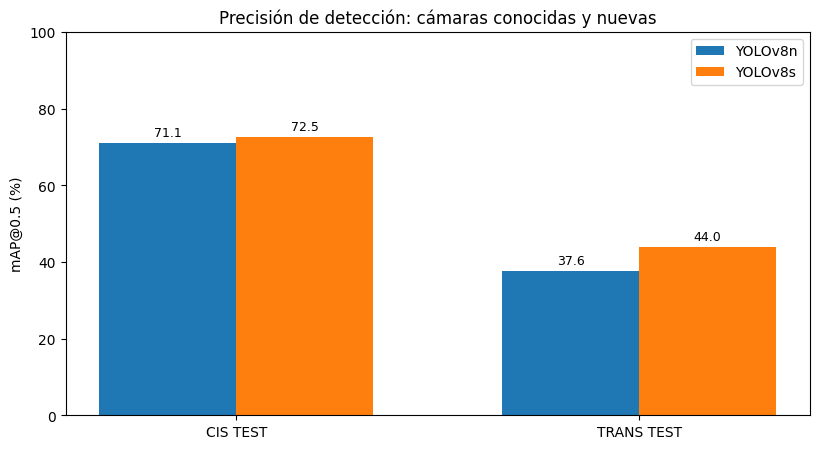

Figura guardada: fig01_mAP_comparacion.png


In [18]:
def exportar_figura(fig, nombre):
    destino = FIGURAS / nombre
    fig.savefig(destino, dpi=250, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print("Figura guardada:",destino.name)

if GENERAR_FIGURAS:
    orden=("cis_test","trans_test")
    fig, ax=plt.subplots(figsize=(8.3,4.6))
    x=np.arange(2)
    ancho=0.34
    for shift, nombre in [(-ancho/2,"YOLOv8n"),(ancho/2,"YOLOv8s")]:
        valores=(metricas_globales[metricas_globales["Modelo"]==nombre]
                 .set_index("Particion").reindex(orden))
        bars=ax.bar(x+shift,valores["mAP50"]*100,ancho,label=nombre)
        ax.bar_label(bars,fmt="%.1f",padding=3,fontsize=9)
    ax.set(xticks=x,xticklabels=("CIS TEST","TRANS TEST"),
           ylabel="mAP@0.5 (%)",ylim=(0,100),
           title="Precisión de detección: cámaras conocidas y nuevas")
    ax.legend()
    fig.tight_layout()
    exportar_figura(fig,"fig01_mAP_comparacion.png")

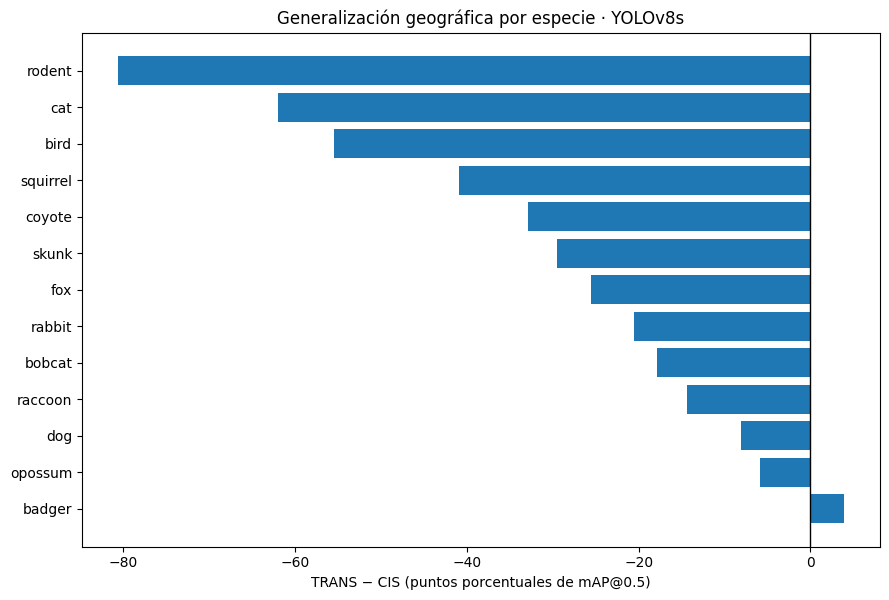

Figura guardada: fig02_brecha_por_especie.png


In [19]:
if GENERAR_FIGURAS:
    tabla=(especies_detalle[especies_detalle["Modelo"]=="YOLOv8s"]
           .sort_values("Brecha_mAP50_pp"))
    fig,ax=plt.subplots(figsize=(9,6.1))
    ax.barh(tabla["Especie"],tabla["Brecha_mAP50_pp"])
    ax.axvline(0,color="black",lw=1)
    ax.set(xlabel="TRANS − CIS (puntos porcentuales de mAP@0.5)",
           title="Generalización geográfica por especie · YOLOv8s")
    ax.invert_yaxis()
    fig.tight_layout()
    exportar_figura(fig,"fig02_brecha_por_especie.png")

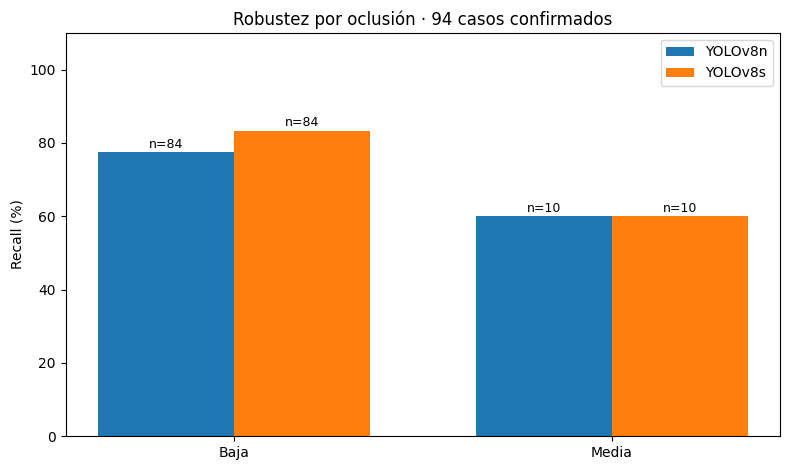

Figura guardada: fig03_oclusion_auditada.png


In [20]:
if GENERAR_FIGURAS:
    resumen=(pred_oclusion.groupby(["Modelo","Oclusion"],as_index=False)
             .agg(Casos=("Detectado","size"),Recall=("Detectado","mean")))
    categorias=[c for c in ("Baja","Media","Alta") if c in resumen["Oclusion"].values]
    x=np.arange(len(categorias))
    fig,ax=plt.subplots(figsize=(8,4.8))
    for shift,modelo in [(-0.18,"YOLOv8n"),(0.18,"YOLOv8s")]:
        datos=resumen[resumen["Modelo"]==modelo].set_index("Oclusion").reindex(categorias)
        barras=ax.bar(x+shift,datos["Recall"]*100,0.36,label=modelo)
        for barra,n in zip(barras,datos["Casos"]):
            ax.annotate(f"n={int(n)}", (barra.get_x()+barra.get_width()/2,
                         barra.get_height()),xytext=(0,3),
                        textcoords="offset points",ha="center",fontsize=9)
    ax.set(xticks=x,xticklabels=categorias,ylabel="Recall (%)",ylim=(0,110),
           title="Robustez por oclusión · 94 casos confirmados")
    ax.legend()
    fig.tight_layout()
    exportar_figura(fig,"fig03_oclusion_auditada.png")

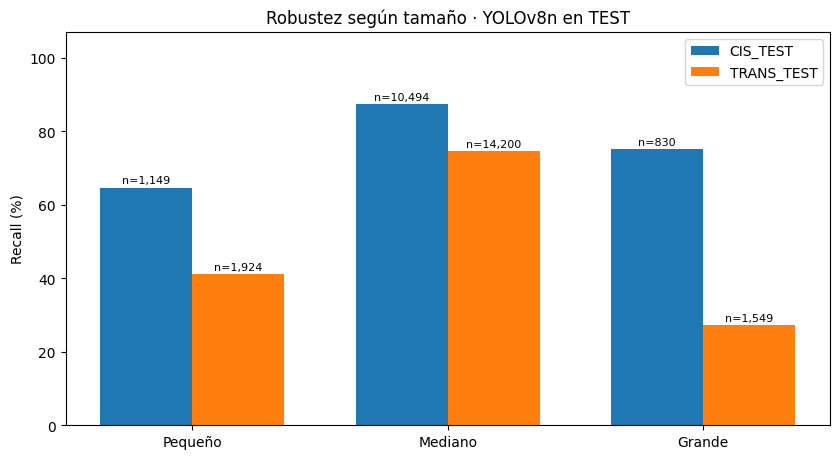

Figura guardada: fig04_tamano_yolov8n.png


In [21]:
if GENERAR_FIGURAS:
    # Solo YOLOv8n; todos los objetos anotados en TEST y particionados por tamaño.
    cats=[c for c in ("Pequeño","Mediano","Grande") if c in robustez_tamano["Tamano"].values]
    x=np.arange(len(cats))
    fig,ax=plt.subplots(figsize=(8.5,4.7))
    for shift,split in [(-0.18,"cis_test"),(0.18,"trans_test")]:
        datos=robustez_tamano[robustez_tamano["Particion"]==split].set_index("Tamano").reindex(cats)
        bars=ax.bar(x+shift,datos["Recall_pct"],0.36,label=split.upper())
        for bar,n in zip(bars,datos["Casos"]):
            ax.annotate(f"n={int(n):,}",
                        (bar.get_x()+bar.get_width()/2,bar.get_height()),
                        xytext=(0,3),textcoords="offset points",ha="center",fontsize=8)
    ax.set(xticks=x,xticklabels=cats,ylabel="Recall (%)",ylim=(0,107),
           title="Robustez según tamaño · YOLOv8n en TEST")
    ax.legend()
    fig.tight_layout()
    exportar_figura(fig,"fig04_tamano_yolov8n.png")

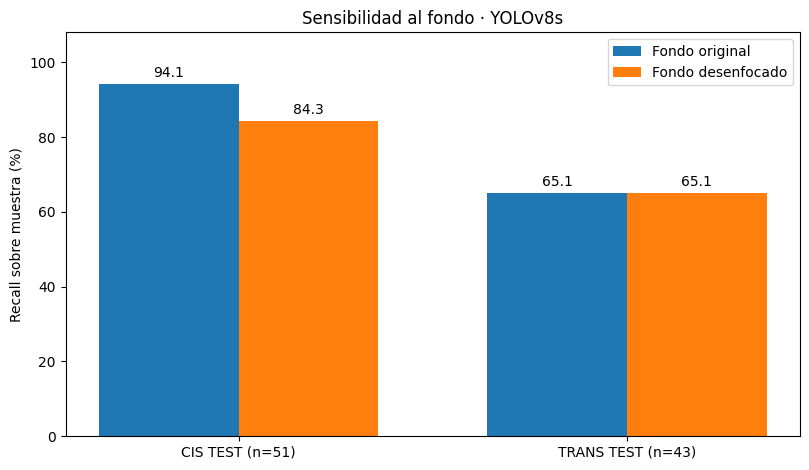

Figura guardada: fig05_sensibilidad_fondo.png


In [22]:
if GENERAR_FIGURAS:
    splits=["cis_test","trans_test"]
    tab=resumen_fondo.set_index("Particion").reindex(splits)
    x=np.arange(2)
    fig,ax=plt.subplots(figsize=(8.2,4.8))
    a=ax.bar(x-.18,tab["Recall_original_pct"],.36,label="Fondo original")
    b=ax.bar(x+.18,tab["Recall_alterado_pct"],.36,label="Fondo desenfocado")
    ax.bar_label(a,fmt="%.1f",padding=3)
    ax.bar_label(b,fmt="%.1f",padding=3)
    ax.set(xticks=x,xticklabels=["CIS TEST (n=51)","TRANS TEST (n=43)"],
           ylabel="Recall sobre muestra (%)",ylim=(0,108),
           title="Sensibilidad al fondo · YOLOv8s")
    ax.legend()
    fig.tight_layout()
    exportar_figura(fig,"fig05_sensibilidad_fondo.png")

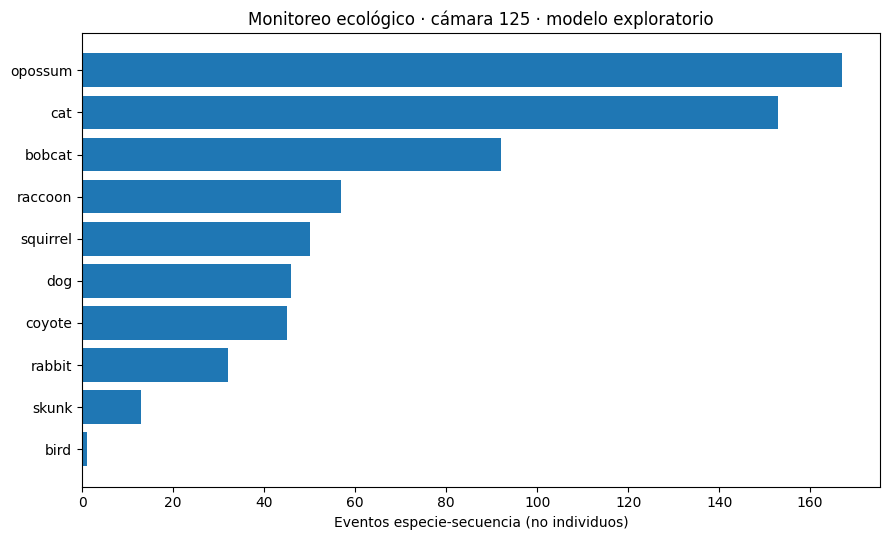

Figura guardada: fig06_eventos_ecologicos.png


In [23]:
if GENERAR_FIGURAS:
    top=(esp_eco.sort_values("Eventos_secuencia",ascending=False).head(12))
    fig,ax=plt.subplots(figsize=(9,5.5))
    ax.barh(top["especie"],top["Eventos_secuencia"])
    ax.invert_yaxis()
    ax.set(xlabel="Eventos especie-secuencia (no individuos)",
           title="Monitoreo ecológico · cámara 125 · modelo exploratorio")
    fig.tight_layout()
    exportar_figura(fig,"fig06_eventos_ecologicos.png")

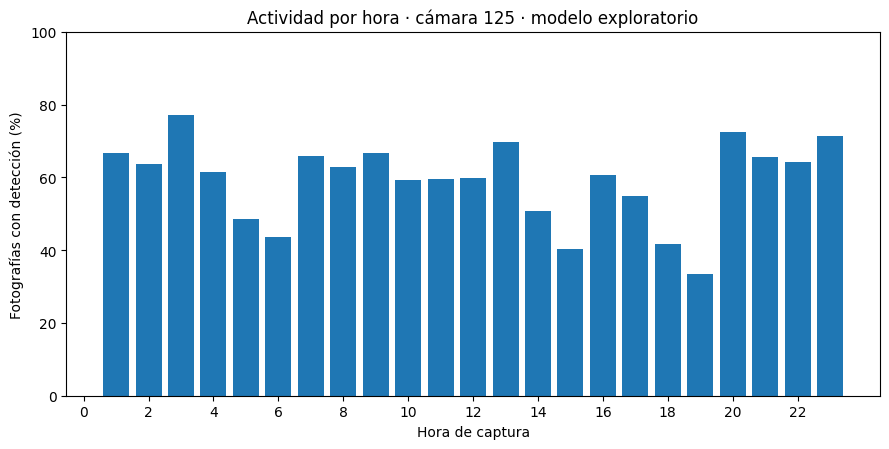

Figura guardada: fig07_actividad_horaria.png


In [24]:
if GENERAR_FIGURAS:
    tmp=fotos_eco.copy()
    tmp["hora"]=pd.to_numeric(tmp["hora"],errors="coerce")
    horas=(tmp.dropna(subset=["hora"]).groupby("hora")
           .agg(Fotografias=("file_name","size"),
                Con_deteccion=("con_fauna_predicha","sum"))
           .reindex(range(24),fill_value=0))
    horas["Tasa"]=(100*horas["Con_deteccion"]/
                   horas["Fotografias"].replace(0,np.nan))
    fig,ax=plt.subplots(figsize=(9,4.6))
    ax.bar(horas.index,horas["Tasa"])
    ax.set(xticks=list(range(0,24,2)),xlabel="Hora de captura",
           ylabel="Fotografías con detección (%)",ylim=(0,100),
           title="Actividad por hora · cámara 125 · modelo exploratorio")
    fig.tight_layout()
    exportar_figura(fig,"fig07_actividad_horaria.png")

## 11 · Síntesis e interpretación responsable

**Resultado global.** YOLOv8s obtuvo mAP@0.5 de **0.7247 CIS TEST** y **0.4396 TRANS TEST**, frente a **0.7107** y **0.3759** de YOLOv8n. En las mismas 13 especies, la brecha geográfica macro fue aproximadamente **−29.98 pp** (YOLOv8s) frente a **−35.03 pp** (YOLOv8n). La degradación en ubicaciones no vistas persiste incluso con el modelo más grande.

**Robustez.** En 94 casos evaluables de oclusión, YOLOv8s detectó 76 y YOLOv8n detectó 71. El recall de oclusión baja fue 83.33% frente a 77.38%; con oclusión media ambos alcanzaron 60%, pero solo hay 10 casos. No hubo casos de oclusión alta confirmados: **no estimable**. La selección manual por tamaño no representa la distribución completa de TEST.

**Contexto.** Al desenfocar el fondo se perdió recall en CIS (−9.81 pp), mientras que el recall agregado en TRANS no cambió. Hubo 6 pérdidas y 1 ganancia global. Esto indica sensibilidad al cambio de contexto en ciertos ejemplos, **no prueba causal de memorización geográfica**. Además, el emparejamiento simplificado del experimento de fondo difiere del usado en robustez por oclusión.

**Monitoreo ecológico.** El módulo de cámara 125 demuestra reporte por periodo y especie a partir de un modelo preliminar, no validación operacional de YOLOv8s. Las imágenes sin detección podrían contener animales no reconocidos, y los eventos de secuencia no representan individuos únicos.

**IA responsable (para expandir a media página del artículo):** en especies amenazadas, falsos negativos pueden subestimar la presencia y priorización de conservación; falsos positivos incrementan la carga de revisión por especialistas. La marcada caída en cámaras nuevas advierte contra decisiones automatizadas fuera de la distribución de entrenamiento. Deben aplicarse revisión humana de alertas sensibles, análisis por ubicación/especie, validaciones en nuevas cámaras, documentación de incertidumbre y no interpretar `sin detección` como `sin fauna`. Las fotos de cámaras trampa pueden contener personas o información de localización sensible: se deben proteger esos datos.

### Pendientes documentados (no inventados)
- Localizar/etiquetar más ejemplos de oclusión alta; si no se encuentran, declarar limitación.
- Si se pide una comparación de robustez por tamaño entre arquitecturas, calcularla para YOLOv8s; por ahora solo existe para YOLOv8n.
- Reunir al menos cinco trabajos relacionados comprobables y redactar el informe NeurIPS de 6–10 páginas.
- Preparar un repositorio GitHub con `README`, dependencias, scripts de ejecución y permisos adecuados para usar los datos originales.
- Si se desea afirmar calidad de monitoreo con YOLOv8s, repetir el reporte ecológico con los pesos finales y evaluar sus errores.

## 12 · Comprobación final de artefactos

Las figuras/tablas se guardaron sin modificar los resultados originales. Se puede desconectar la GPU después de confirmar los archivos. Los CSV siguen en Drive aunque el kernel de Colab se reinicie.

In [25]:
print("Figuras publicables:")
for p in sorted(FIGURAS.glob("fig0*.png")):
    print(" ·",p.name, f"({p.stat().st_size/1024:.0f} KB)")
print("\nTablas publicables:")
for p in sorted(TABLAS.glob("*.csv")):
    print(" ·",p.name)
print("\nOriginales sin sobreescribir:", RESULTADOS)

Figuras publicables:
 · fig01_comparacion_arquitecturas.png (66 KB)
 · fig01_mAP_comparacion.png (68 KB)
 · fig02_brecha_por_especie.png (95 KB)
 · fig03_oclusion_auditada.png (61 KB)
 · fig03_robustez_oclusion.png (60 KB)
 · fig04_tamano_yolov8n.png (76 KB)
 · fig05_sensibilidad_fondo.png (76 KB)
 · fig06_eventos_ecologicos.png (82 KB)
 · fig07_actividad_horaria.png (71 KB)

Tablas publicables:
 · brecha_geografica_13_especies.csv
 · brecha_geografica_modelos.csv
 · comparacion_modelos.csv
 · generalizacion_13_especies.csv
 · generalizacion_ambos_modelos_13_especies.csv
 · mAP_por_especie_y_geografia.csv
 · robustez_oclusion.csv
 · robustez_tamano_sensibilidad.csv
 · robustez_tamano_yolov8n.csv
 · sensibilidad_fondo.csv

Originales sin sobreescribir: /content/drive/MyDrive/examen_yolo/resultados_analisis
